# Diversité des modèles du benchmark

Évaluer les domaines couverts, les liens entre problèmes et la variété des matrices de transition et de récompense. Les effectifs du catalogue, la sélection proposée et les instances effectivement analysées sont présentés séparément. Aucun solveur ni calcul de valeur optimale n'est lancé.

Utiliser le noyau Conda `benchmark`, avec les dépendances `mdpforge[notebooks]` installées depuis ce dépôt. Pour actualiser l'étude après une modification du code, redémarrer le noyau puis exécuter toutes les cellules. Les modèles et presets sont redécouverts à chaque exécution ; les nouveaux modèles ne demandent aucune modification de la liste de chargement.

Par défaut, l'inventaire couvre les deux catalogues et tous leurs presets ; l'analyse numérique porte sur `tiny`, avec des seuils de travail explicites. Elle construit réellement les modèles et peut donc prendre du temps. Les seuils de dimensions ne constituent pas une limite stricte de mémoire ou de durée : certains constructeurs explorent déjà leur espace d'états. Mettre `ANALYZE_MATRICES = False` pour consulter uniquement l'inventaire.

In [1]:
import gc
import hashlib
import inspect
import json
import platform
import random
import subprocess
import warnings
from datetime import datetime, timezone
from importlib import import_module, metadata
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.sparse.csgraph import connected_components

import mdpforge
from mdpforge.core.validation import validate_model
from mdpforge.models import discounted, total
from mdpforge.models.discounted._jani.reader import JANIStateLimitError
from mdpforge.utils.persistence import model_cache_path

REPO_ROOT = next(
    path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file() and (path / "src/mdpforge").is_dir()
)
if not Path(mdpforge.__file__).resolve().is_relative_to(REPO_ROOT / "src"):
    raise RuntimeError("Installer mdpforge depuis ce checkout avant l'analyse.")

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_rows", 30)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True})

## 1. Périmètre et protocole

`MODEL_IDS = None` sélectionne toutes les recettes des critères choisis. Pour décrire une campagne précise, renseigner ses identifiants, par exemple `{"discounted:rooms", "total:rooms"}`, et ses presets. Un identifiant est une recette du catalogue, pas une famille indépendante. Le critère moyen réutilise les modèles discounted : il ne constitue pas un troisième catalogue de problèmes.

Les seuils écartent une instance avec une raison visible ; aucun preset de remplacement n'est utilisé. Le cache garde sa politique habituelle `readwrite` : ni purge ni calcul de référence. L'état des générateurs globaux NumPy et Python est restauré autour de chaque construction. La graine de cette analyse ne remplace pas les graines internes propres aux recettes.

In [2]:
CRITERIA = ("discounted", "total")
MODEL_IDS = None
CATEGORIES = None
PRESETS = ("tiny",)
ANALYZE_MATRICES = True
SEED = 0
CACHE_MODE = "readwrite"
MAX_REQUESTED_STATES = 10_000
MAX_ACTUAL_STATES = 20_000
MAX_STATE_ACTIONS = 1_000_000
MAX_TRANSITION_NNZ = 5_000_000
ANALYZE_GRAPH = True
MAX_ACTION_COMPARISON_WORK = 20_000_000
ATOL = 1e-12
PREVIEW_ID = "discounted:rooms"
PREVIEW_PRESET = "tiny"
PREVIEW_ACTION = 0
PREVIEW_STATES = 60
EXPORT = True
OUTPUT_ROOT = REPO_ROOT / "artifacts/tmp/model_diversity"

# Annotations relues : parenté de tâche, sans prétendre à l'équivalence des MDP.
# Une clé nue s'applique aux deux critères ; une clé qualifiée est prioritaire.
ANNOTATIONS = {
    "rooms": {
        "family": "four_rooms",
        "task": "Navigation vers une sortie dans quatre pièces",
        "evidence": "Description et référence Hengst dans les deux modules rooms.py.",
    },
    "maze_prims": {
        "family": "generated_maze",
        "task": "Navigation dans un labyrinthe généré",
        "evidence": "Description du module maze_prims.py : générateur de Prim.",
    },
    "maze_wilson": {
        "family": "generated_maze",
        "task": "Navigation dans un labyrinthe généré",
        "evidence": "Description du module maze_wilson.py : générateur de Wilson.",
    },
    "maze_backtrack": {
        "family": "generated_maze",
        "task": "Navigation dans un labyrinthe généré",
        "evidence": "Description du module maze_backtrack.py : génération par retour arrière.",
    },
    "discounted:consensus": {
        "family": "shared_coin_consensus",
        "origin": "PRISM",
        "task": "Coût de terminaison du consensus",
        "evidence": "Description et docstring du module consensus.py.",
    },
    "discounted:qvbs_consensus": {
        "family": "shared_coin_consensus",
        "origin": "qvbs",
        "task": "Coût de terminaison du consensus",
        "evidence": "Description et docstring du module qvbs_consensus.py.",
    },
    "discounted:jani_rabin": {
        "family": "rabin_mutual_exclusion",
        "origin": "jani-models",
        "evidence": "Description Rabin mutual exclusion et source_collection du module.",
    },
    "discounted:prism_rabin": {
        "family": "rabin_mutual_exclusion",
        "origin": "PRISM",
        "evidence": "Description et docstring du module prism_rabin.py.",
    },
}

# Renseigner family, origin, task, objective, temporal_type, evidence si connus.
# Une valeur absente reste inconnue, même si un nom suggère une parenté.
CATALOGUES = {"discounted": discounted, "total": total}
if not CRITERIA or set(CRITERIA) - CATALOGUES.keys():
    raise ValueError("CRITERIA doit contenir discounted et/ou total.")
if not PRESETS or len(set(PRESETS)) != len(PRESETS):
    raise ValueError("PRESETS doit être une séquence non vide sans doublons.")

In [3]:
catalogue_rows = []
preset_rows = []
entries_by_id = {}
for criterion in CRITERIA:
    for entry in CATALOGUES[criterion].list_models():
        model_id = f"{criterion}:{entry['name']}"
        entries_by_id[model_id] = entry
        annotation = ANNOTATIONS.get(model_id, ANNOTATIONS.get(entry["name"], {}))
        row = {
            "model_id": model_id,
            "criterion": criterion,
            "recipe": entry["name"],
            "category": entry.get("category"),
            "description": entry.get("description"),
            "reference": entry.get("reference"),
            "available": entry.get("available", True),
            "unavailable_reason": entry.get("reason"),
            "family": annotation.get("family"),
            "task": annotation.get("task"),
            "objective": annotation.get("objective"),
            "temporal_type": annotation.get("temporal_type"),
            "origin": annotation.get("origin", entry.get("source_collection")),
            "annotation_evidence": annotation.get("evidence"),
            "source_url": entry.get("source_url"),
        }
        row["family_reviewed"] = bool(row["family"] and row["annotation_evidence"])
        if row["family"] and not row["family_reviewed"]:
            raise ValueError(
                f"Une famille annotée doit avoir une justification : {model_id}"
            )
        row["selected"] = (MODEL_IDS is None or model_id in MODEL_IDS) and (
            CATEGORIES is None or row["category"] in CATEGORIES
        )
        catalogue_rows.append(row)
        for preset, options in entry.get("sizes", {}).items():
            preset_rows.append(
                {
                    "model_id": model_id,
                    "preset": preset,
                    "requested_states": options.get("requested_state_dim"),
                    "parameters": options.get("parameters"),
                    "preset_available": options.get("parameters") is not None,
                    "preset_reason": options.get("reason"),
                }
            )

catalogue = pd.DataFrame(catalogue_rows)
presets = pd.DataFrame(preset_rows)
if MODEL_IDS is not None and set(MODEL_IDS) - set(catalogue.model_id):
    raise ValueError(
        f"Identifiants inconnus : {set(MODEL_IDS) - set(catalogue.model_id)}"
    )
if CATEGORIES is not None and set(CATEGORIES) - set(catalogue.category):
    raise ValueError(
        f"Catégories inconnues : {set(CATEGORIES) - set(catalogue.category)}"
    )
if set(PRESETS) - set(presets.preset):
    raise ValueError(f"Presets inconnus : {set(PRESETS) - set(presets.preset)}")
selected = catalogue.loc[catalogue.selected].copy()
if selected.empty:
    raise ValueError("La sélection est vide.")
display(
    pd.DataFrame(
        {
            "catalogue": [len(catalogue), catalogue.available.sum()],
            "selection": [len(selected), selected.available.sum()],
        },
        index=["recettes", "recettes déclarées disponibles"],
    )
)
display(selected.sort_values(["category", "model_id"]))

,catalogue,selection
recettes,139,139
recettes déclarées disponibles,134,134


,model_id,criterion,recipe,category,description,reference,available,unavailable_reason,family,task,objective,temporal_type,origin,annotation_evidence,source_url,family_reviewed,selected
6,discounted:block,discounted,block,abstract,Random transition blocks with weak connections between blocks.,Meuleau et al. (1998). Solving very large weakly coupled Markov decision processes. AAAI.,True,NaN,NaN,NaN,None,None,NaN,NaN,NaN,False,True
11,discounted:chain_walk,discounted,chain_walk,abstract,Controlled chain walk with uncertain movement and boundary rewards.,"Lagoudakis, M. G. and Parr, R. (2003). Least-Squares Policy Iteration. JMLR 4:1107-1149.",True,NaN,NaN,NaN,None,None,NaN,NaN,NaN,False,True
23,discounted:garnet,discounted,garnet,abstract,Random finite MDP with Gaussian rewards and normalized random transitions.,"Bhatnagar, S. et al. (2009). Natural actor-critic algorithms. Automatica 45(11):2471-2482.",True,NaN,NaN,NaN,None,None,NaN,NaN,NaN,False,True
29,discounted:jani_approx_pi,discounted,jani_approx_pi,abstract,Monte Carlo approximation of pi,https://github.com/ahartmanns/jani-models/tree/5e2fd8fa31778ad7e06b298b2d3e333ba450b042/ApproxPi,True,NaN,NaN,NaN,None,None,jani-models,NaN,https://github.com/ahartmanns/jani-models/tree/5e2fd8fa31778ad7e06b298b2d3e333ba450b042/ApproxPi,False,True
32,discounted:jani_coupon_collector,discounted,jani_coupon_collector,abstract,Coupon collection from an urn,https://github.com/ahartmanns/jani-models/tree/5e2fd8fa31778ad7e06b298b2d3e333ba450b042/CouponCo...,True,NaN,NaN,NaN,None,None,jani-models,NaN,https://github.com/ahartmanns/jani-models/tree/5e2fd8fa31778ad7e06b298b2d3e333ba450b042/CouponCo...,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100,discounted:traffic_control,discounted,traffic_control,service_operations,Two queues with independent arrivals and costly traffic-light switches.,IPPC 2011 Traffic Control RDDL benchmark (inspiration): https://users.cecs.anu.edu.au/~ssanner/I...,True,NaN,NaN,NaN,None,None,NaN,NaN,NaN,False,True
105,discounted:zenotravel,discounted,zenotravel,service_operations,"Single-aircraft passenger delivery with fuel, refuelling and flight failure.","Younes et al., JAIR 24 (2005), IPPC 2004 Zeno Travel: https://www.cs.cmu.edu/afs/cs/project/jair...",True,NaN,NaN,NaN,None,None,NaN,NaN,NaN,False,True
110,total:boxworld,total,boxworld,service_operations,Deliver a crate with traffic delays and absorbing cargo damage.,"Younes et al., JAIR 24 (2005), IPPC 2004 Boxworld: https://www.cs.cmu.edu/afs/cs/project/jair/pu...",True,NaN,NaN,NaN,None,None,NaN,NaN,NaN,False,True
134,total:taxi,total,taxi,service_operations,Pick up and deliver a passenger with reward only for final delivery.,"Dietterich, T. G. (2000). Hierarchical reinforcement learning with the MAXQ value function decom...",True,NaN,NaN,NaN,None,None,NaN,NaN,NaN,False,True


## 2. Couverture des tâches et liens entre recettes

Les catégories sont celles du catalogue, sans reclassement automatique. Les familles sont des regroupements explicites de tâches, documentés dans `ANNOTATIONS` ; cette première liste est partielle. La même famille peut réunir plusieurs dynamiques ou objectifs. Les origines non renseignées restent inconnues : un préfixe de module n'est pas une preuve de provenance.

Le nombre exact de familles ne peut pas être établi tant que les parentés restantes n'ont pas été relues. Le tableau affiche donc les familles annotées et les recettes sans regroupement séparément. Les comptages d'instances ne sont jamais présentés comme des comptages de familles indépendantes.

,catalogue,selection
category,,
abstract,11,11
asset_management,12,12
distributed_systems,28,28
games_and_puzzles,13,13
navigation,50,50
service_operations,25,25


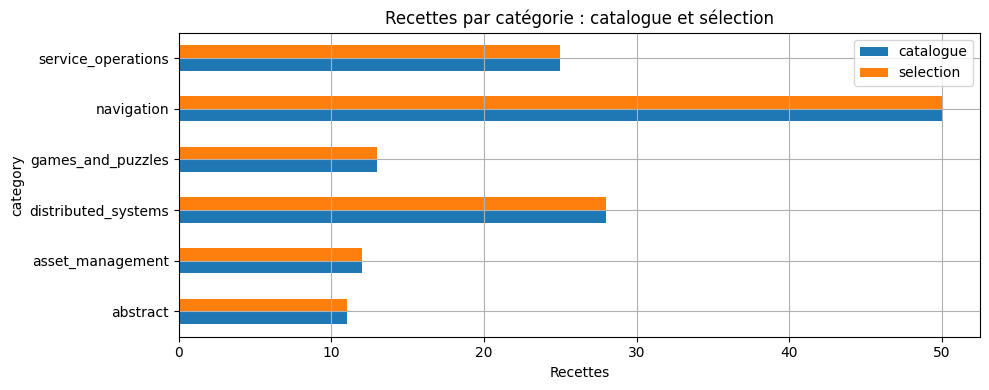

,recipes,annotated_families,unreviewed_recipes
category,,,
abstract,11,0,11
asset_management,12,0,12
distributed_systems,28,2,24
games_and_puzzles,13,0,13
navigation,50,2,42
service_operations,25,0,25


origin,PRISM,inconnue,jani-models,qvbs
category,,,,
abstract,0,7,3,1
asset_management,0,12,0,0
distributed_systems,2,9,6,11
games_and_puzzles,0,10,0,3
navigation,0,46,0,4
service_operations,0,17,5,3


,recipes,criteria,evidence
family,,,
four_rooms,"[discounted:rooms, total:rooms]","[discounted, total]","[Description et référence Hengst dans les deux modules rooms.py., Description et référence Hengs..."
generated_maze,"[discounted:maze_backtrack, discounted:maze_prims, discounted:maze_wilson, total:maze_backtrack,...","[discounted, total]","[Description du module maze_backtrack.py : génération par retour arrière., Description du module..."
rabin_mutual_exclusion,"[discounted:jani_rabin, discounted:prism_rabin]",[discounted],"[Description Rabin mutual exclusion et source_collection du module., Description et docstring du..."
shared_coin_consensus,"[discounted:consensus, discounted:qvbs_consensus]",[discounted],"[Description et docstring du module consensus.py., Description et docstring du module qvbs_conse..."


,model_id,description,reference
0,discounted:access_control,Accept or reject priority requests with limited free servers.,"Sutton, R. S. and Barto, A. G. (2018). Reinforcement Learning: An Introduction, 2nd ed., Example..."
1,discounted:acrobot,Discretized control of an underactuated two-link pendulum.,"Sutton, R. S. (1996). Generalization in Reinforcement Learning: Successful Examples Using Sparse..."
2,discounted:admission,Admission control with customer classes and service phases.,"Wieczorek, Busic, and Hyon: admission-control / critical-level-policy model, adapted from pyAdmi..."
3,discounted:ambulance,One-dimensional ambulance positioning under random demand.,"Mason, W. A. and Watts, D. J. (2012). Collaborative learning in networks. PNAS 109(3):764-769."
4,discounted:ambulance_relocation,Ambulance relocation with response and movement costs.,"Sinclair, Banerjee & Yu (2019), Adaptive Discretization for Episodic RL."
...,...,...,...
134,total:taxi,Pick up and deliver a passenger with reward only for final delivery.,"Dietterich, T. G. (2000). Hierarchical reinforcement learning with the MAXQ value function decom..."
135,total:tireworld,Reach a road destination despite punctures and absorbing stranding.,"IPPC 2004 Tireworld (Younes et al., JAIR 2005): https://ipc04.icaps-conference.org/probabilistic/"
136,total:windgrid,Reach an absorbing grid goal under column-dependent wind.,"Sutton & Barto, Reinforcement Learning: An Introduction, Example 6.5, Windy Gridworld."
137,total:wumpus_world,"Retrieve gold and exit safely, retaining death and empty-handed exit.","Wumpus World, Russell & Norvig, Artificial Intelligence: A Modern Approach; used as a discrete-s..."


preset,large,medium,small,tiny
category,,,,
abstract,7,7,11,11
asset_management,12,12,12,12
distributed_systems,13,19,28,28
games_and_puzzles,10,10,13,13
navigation,47,49,50,50
service_operations,19,19,20,20


,model_id,preset,preset_reason
79,discounted:firewire,large,The original concrete FireWire benchmark provides only delay=3 and delay=36; no third configurat...
112,discounted:jani_3_tandem_queue,tiny,Source type sta requires a finite discrete-time MDP adaptation before benchmarking.
113,discounted:jani_3_tandem_queue,small,Source type sta requires a finite discrete-time MDP adaptation before benchmarking.
114,discounted:jani_3_tandem_queue,medium,Source type sta requires a finite discrete-time MDP adaptation before benchmarking.
115,discounted:jani_3_tandem_queue,large,Source type sta requires a finite discrete-time MDP adaptation before benchmarking.
...,...,...,...
330,discounted:qvbs_triangle_tireworld,medium,No additional distinct published tractable size; runtime calibration is pending.
331,discounted:qvbs_triangle_tireworld,large,No additional distinct published tractable size; runtime calibration is pending.
339,discounted:qvbs_wlan_dl,large,No additional distinct published tractable size; runtime calibration is pending.
342,discounted:qvbs_zenotravel,medium,No additional distinct published tractable size; runtime calibration is pending.


In [4]:
coverage = (
    catalogue.groupby("category")
    .size()
    .rename("catalogue")
    .to_frame()
    .join(selected.groupby("category").size().rename("selection"))
    .fillna(0)
    .astype(int)
)
display(coverage)
coverage.plot.barh(
    title="Recettes par catégorie : catalogue et sélection", xlabel="Recettes"
)
plt.tight_layout()
plt.show()

family_coverage = selected.groupby("category").agg(
    recipes=("model_id", "size"),
    annotated_families=("family", "nunique"),
    unreviewed_recipes=("family_reviewed", lambda values: int((~values).sum())),
)
display(family_coverage)
display(pd.crosstab(selected.category, selected.origin.fillna("inconnue")))
family_groups = (
    selected.loc[selected.family_reviewed]
    .groupby("family")
    .agg(
        recipes=("model_id", list),
        criteria=("criterion", lambda x: sorted(set(x))),
        evidence=("annotation_evidence", list),
    )
)
display(family_groups)
display(
    selected.loc[~selected.family_reviewed, ["model_id", "description", "reference"]]
)

preset_coverage = presets.merge(selected[["model_id", "category"]], on="model_id")
display(
    pd.crosstab(
        preset_coverage.category,
        preset_coverage.preset,
        values=preset_coverage.preset_available,
        aggfunc="sum",
    ).fillna(0)
)
display(
    preset_coverage.loc[
        ~preset_coverage.preset_available, ["model_id", "preset", "preset_reason"]
    ]
)

## 3. Définition des mesures numériques

Pour chaque instance, `P[a][s,t]` est la probabilité de passer de `s` à `t` sous l'action `a`, et `R[s,a]` la récompense moyenne immédiate. Les statistiques donnent le même poids à chaque couple état-action ; elles ne décrivent pas une distribution de visite sous une politique. Les graphiques de synthèse donnent le même poids à chaque instance analysée ; des presets multiples surreprésentent donc les recettes qui en ont davantage.

Les transitions sont étudiées sur des copies CSR canoniques : les doublons sont additionnés et les zéros stockés sont retirés, sans modifier le modèle. On mesure le nombre de probabilités strictement positives, la densité `nnz / (A × S²)`, la distribution des nombres de successeurs, la proportion de lignes déterministes, l'entropie moyenne en bits et la probabilité moyenne de rester sur place. L'entropie vaut zéro pour une transition déterministe ; elle augmente lorsque la probabilité se répartit entre plusieurs successeurs.

Un état est dit absorbant si toutes les actions restent sur cet état avec probabilité 1, à `ATOL` près. Cela ne suffit pas à lui donner le sens de « fin de tâche ». Les états terminaux déclarés par le modèle sont comptés séparément ; l'absence de déclaration donne une valeur manquante, pas zéro.

Les récompenses sont décrites par leurs quantiles, moyenne, écart-type, amplitude et proportions nulles, positives et négatives. On distingue une récompense globale constante et une récompense qui varie entre actions dans un même état. La valeur zéro et l'égalité des récompenses sont traitées exactement ; aucune normalisation n'est appliquée.

Deux actions d'un état sont identiques ici si leurs distributions de transition et leurs récompenses sont exactement égales. Cette mesure repère notamment les emplacements d'actions répétés par certains imports ; elle ne prouve pas que les actions distinctes ont des qualités différentes. Le calcul est omis au-delà du budget indiqué.

In [5]:
def transition_metrics(transitions):
    """Décrire les probabilités et les supports sans changer les matrices."""
    states = transitions[0].shape[0]
    absorbing = np.ones(states, dtype=bool)
    degrees = []
    action_rows = []
    for action, matrix in enumerate(transitions):
        degree = np.diff(matrix.indptr)
        diagonal = matrix.diagonal()
        row_sum = np.asarray(matrix.sum(axis=1)).ravel()
        deterministic = (degree == 1) & np.isclose(row_sum, 1, atol=ATOL, rtol=0)
        absorbing &= (degree == 1) & np.isclose(diagonal, 1, atol=ATOL, rtol=0)
        entropy = -np.sum(matrix.data * np.log2(matrix.data)) / states
        action_rows.append(
            {
                "action": action,
                "transition_nnz": matrix.nnz,
                "transition_density": matrix.nnz / states**2,
                "successors_min": degree.min(),
                "successors_median": np.median(degree),
                "successors_p90": np.quantile(degree, 0.9),
                "successors_max": degree.max(),
                "successors_mean": degree.mean(),
                "deterministic_share": deterministic.mean(),
                "self_loop_mass_mean": diagonal.mean(),
                "entropy_bits_mean": entropy,
                "row_sum_error_max": np.max(np.abs(row_sum - 1)),
            }
        )
        degrees.append(degree)
    degrees = np.concatenate(degrees)
    actions = len(transitions)
    table = pd.DataFrame(action_rows)
    result = {
        "transition_nnz": int(table.transition_nnz.sum()),
        "transition_density": table.transition_nnz.sum() / (actions * states**2),
        "successors_min": int(degrees.min()),
        "successors_median": np.median(degrees),
        "successors_p90": np.quantile(degrees, 0.9),
        "successors_max": int(degrees.max()),
        "successors_mean": degrees.mean(),
        "deterministic_share": table.deterministic_share.mean(),
        "self_loop_mass_mean": table.self_loop_mass_mean.mean(),
        "entropy_bits_mean": table.entropy_bits_mean.mean(),
        "absorbing_states": int(absorbing.sum()),
        "absorbing_share": absorbing.mean(),
        "row_sum_error_max": table.row_sum_error_max.max(),
    }
    return result, action_rows


def reward_metrics(rewards):
    """Décrire les valeurs de récompense et leur variation entre actions."""
    return {
        "reward_min": rewards.min(),
        "reward_p10": np.quantile(rewards, 0.1),
        "reward_median": np.median(rewards),
        "reward_p90": np.quantile(rewards, 0.9),
        "reward_max": rewards.max(),
        "reward_mean": rewards.mean(),
        "reward_std": rewards.std(),
        "reward_range": np.ptp(rewards),
        "reward_zero_share": np.mean(rewards == 0),
        "reward_positive_share": np.mean(rewards > 0),
        "reward_negative_share": np.mean(rewards < 0),
        "reward_constant": bool(np.all(rewards == rewards.flat[0])),
        "reward_action_varying_state_share": np.mean(np.ptp(rewards, axis=1) != 0),
    }


def action_metrics(transitions, rewards):
    """Compter les actions distinctes par état par comparaison exacte."""
    actions = len(transitions)
    work = (actions - 1) * sum(matrix.nnz for matrix in transitions)
    if work > MAX_ACTION_COMPARISON_WORK:
        return {
            "action_comparison_status": "budget",
            "distinct_actions_mean": np.nan,
            "distinct_action_share": np.nan,
            "single_choice_state_share": np.nan,
        }
    counts = np.ones(rewards.shape[0], dtype=int)
    for action in range(1, actions):
        repeated = np.zeros(rewards.shape[0], dtype=bool)
        for previous in range(action):
            difference = transitions[action] - transitions[previous]
            difference.eliminate_zeros()
            repeated |= (np.diff(difference.indptr) == 0) & (
                rewards[:, action] == rewards[:, previous]
            )
        counts += ~repeated
    return {
        "action_comparison_status": "computed",
        "distinct_actions_mean": counts.mean(),
        "distinct_action_share": counts.mean() / actions,
        "single_choice_state_share": np.mean(counts == 1),
    }

Le graphe optionnel réunit les transitions de probabilité strictement positive de toutes les actions. Ses composantes fortement connexes sont des groupes d'états où chaque état peut rejoindre les autres dans ce graphe. Les composantes sans sortie et les cycles entre états distincts sont également comptés. Un parcours peut demander des actions différentes selon l'état : ces mesures ne certifient ni la terminaison sous toute politique, ni une propriété unichain, ni la finitude du rendement total. Les boucles sur soi sont décrites séparément.

In [6]:
def graph_metrics(transitions):
    """Décrire le graphe réunissant les supports de toutes les actions."""
    if not ANALYZE_GRAPH:
        return {"graph_status": "disabled"}
    graph = transitions[0].astype(bool)
    for matrix in transitions[1:]:
        graph = graph.maximum(matrix.astype(bool))
    count, labels = connected_components(graph, directed=True, connection="strong")
    sizes = np.bincount(labels, minlength=count)
    edges = graph.tocoo()
    crossing = labels[edges.row] != labels[edges.col]
    outgoing_components = np.unique(labels[edges.row[crossing]])
    return {
        "graph_status": "computed",
        "scc_count": count,
        "largest_scc_share": sizes.max() / graph.shape[0],
        "sink_scc_count": count - len(outgoing_components),
        "nontrivial_cycle_state_share": np.mean(sizes[labels] > 1),
    }


def matrix_fingerprint(transitions, rewards):
    """Identifier les matrices canoniques dans leur ordre actuel."""
    digest = hashlib.sha256()
    for matrix in transitions:
        digest.update(np.asarray(matrix.shape, dtype="<i8").tobytes())
        for values, dtype in (
            (matrix.indptr, "<i8"),
            (matrix.indices, "<i8"),
            (matrix.data, "<f8"),
        ):
            digest.update(np.asarray(values, dtype=dtype).tobytes())
    digest.update(np.asarray(rewards.shape, dtype="<i8").tobytes())
    digest.update(np.asarray(rewards, dtype="<f8").tobytes())
    return digest.hexdigest()


def declared_count(model, plural, singular):
    """Compter une déclaration disponible sans inférer sa signification."""
    if hasattr(model, plural):
        values = getattr(model, plural)
        return len(values) if values is not None else np.nan
    if hasattr(model, singular):
        return 1 if getattr(model, singular) is not None else np.nan
    return np.nan

In [7]:
plan = (
    selected[["model_id", "criterion", "recipe", "category", "available"]]
    .merge(pd.DataFrame({"preset": PRESETS}), how="cross")
    .merge(presets, how="left", on=["model_id", "preset"])
)
display(
    plan[
        [
            "model_id",
            "preset",
            "requested_states",
            "parameters",
            "preset_available",
            "preset_reason",
        ]
    ]
)

,model_id,preset,requested_states,parameters,preset_available,preset_reason
0,discounted:access_control,tiny,500.0,{},True,NaN
1,discounted:acrobot,tiny,1000.0,{},True,NaN
2,discounted:admission,tiny,880.0,{},True,NaN
3,discounted:ambulance,tiny,500.0,{},True,NaN
4,discounted:ambulance_relocation,tiny,500.0,{},True,NaN
...,...,...,...,...,...,...
134,total:taxi,tiny,600.0,{},True,NaN
135,total:tireworld,tiny,1560.0,{},True,NaN
136,total:windgrid,tiny,1200.0,{},True,NaN
137,total:wumpus_world,tiny,680.0,{},True,NaN


In [8]:
def analyze_instance(item):
    """Construire une instance puis en extraire seulement des descriptions."""
    row = dict(item)
    row.update(status="pending", reason=None, stage="selection", warnings=None)
    if not row["available"]:
        row.update(
            status="unavailable", reason=entries_by_id[row["model_id"]].get("reason")
        )
        return row, [], None
    if pd.isna(row["preset_available"]) or not row["preset_available"]:
        reason = (
            row["preset_reason"] if pd.notna(row["preset_reason"]) else "Preset absent."
        )
        row.update(status="unavailable_preset", reason=reason)
        return row, [], None
    if not ANALYZE_MATRICES:
        row.update(status="disabled", reason="Inventaire seul.")
        return row, [], None
    if row["requested_states"] > MAX_REQUESTED_STATES:
        row.update(status="budget", reason="Cible supérieure à MAX_REQUESTED_STATES.")
        return row, [], None

    numpy_state, python_state = np.random.get_state(), random.getstate()
    model = None
    action_rows = []
    preview_data = None
    start = perf_counter()
    caught = []
    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            np.random.seed(SEED)
            random.seed(SEED)
            row["stage"] = "construction"
            constructor = import_module(
                f"mdpforge.models.{row['criterion']}.{row['recipe']}"
            ).Model
            options = dict(row["parameters"])
            options["state_dim"] = int(row["requested_states"])
            # Une limite publique est utilisée seulement si le constructeur l'expose.
            if "state_limit" in inspect.signature(constructor).parameters:
                options["state_limit"] = min(
                    options.get("state_limit") or MAX_ACTUAL_STATES, MAX_ACTUAL_STATES
                )
            row["constructor_options"] = options
            model = constructor(**options)
            row.update(
                model_name=model.name, states=model.state_dim, actions=model.action_dim
            )
            if (
                model.state_dim > MAX_ACTUAL_STATES
                or model.state_dim * model.action_dim > MAX_STATE_ACTIONS
            ):
                row.update(
                    status="budget", reason="Dimensions réelles au-delà du budget."
                )
                return row, [], None
            expected_shape = (model.state_dim, model.action_dim)
            row["cache_present_before"] = model_cache_path(model).exists()
            model.create_model(cache=CACHE_MODE)
            row["build_seconds"] = perf_counter() - start
            if (model.state_dim, model.action_dim) != expected_shape:
                raise ValueError(
                    "Les dimensions après create_model diffèrent du constructeur."
                )
            row["model_config"] = model.get_config()
            row["declared_terminal_states"] = declared_count(
                model, "terminal_states", "terminal_state"
            )
            row["declared_initial_states"] = declared_count(
                model, "initial_states", "initial_state"
            )
            row["state_action_pairs"] = model.state_dim * model.action_dim
            row["state_target_ratio"] = model.state_dim / row["requested_states"]
            row["stage"] = "matrix_budget"
            stored_nnz = sum(matrix.nnz for matrix in model.transition_matrix)
            if stored_nnz > MAX_TRANSITION_NNZ:
                row.update(
                    status="budget",
                    reason="Stockage CSR au-delà de MAX_TRANSITION_NNZ.",
                )
                return row, [], None
            row["stage"] = "matrix_validation"
            validate_model(model)
            row["matrix_validation"] = "passed"
            row["stage"] = "description"
            transitions = []
            for matrix in model.transition_matrix:
                matrix = matrix.copy()
                matrix.sum_duplicates()
                matrix.eliminate_zeros()
                matrix.sort_indices()
                transitions.append(matrix)
            rewards = model.reward_matrix
            metrics, action_rows = transition_metrics(transitions)
            row.update(metrics)
            row.update(reward_metrics(rewards))
            row.update(action_metrics(transitions, rewards))
            row.update(graph_metrics(transitions))
            row["matrix_sha256"] = matrix_fingerprint(transitions, rewards)
            row["matrix_storage_mib"] = (
                sum(
                    m.data.nbytes + m.indices.nbytes + m.indptr.nbytes
                    for m in model.transition_matrix
                )
                + rewards.nbytes
            ) / 2**20
            for action_row in action_rows:
                action = action_row["action"]
                action_row.update(
                    model_id=row["model_id"],
                    preset=row["preset"],
                    reward_min=rewards[:, action].min(),
                    reward_max=rewards[:, action].max(),
                    reward_zero_share=np.mean(rewards[:, action] == 0),
                )
            if (row["model_id"], row["preset"]) == (PREVIEW_ID, PREVIEW_PRESET):
                if not 0 <= PREVIEW_ACTION < model.action_dim:
                    raise ValueError(
                        "PREVIEW_ACTION n'est pas une action de cette instance."
                    )
                stop = min(PREVIEW_STATES, model.state_dim)
                preview_data = {
                    "transition": transitions[PREVIEW_ACTION][:stop, :stop].toarray(),
                    "reward": rewards[:stop, :].copy(),
                    "successors": np.concatenate(
                        [np.diff(m.indptr) for m in transitions]
                    ),
                    "reward_values": rewards.ravel().copy(),
                    "states": model.state_dim,
                    "actions": model.action_dim,
                }
            row.update(status="analyzed", stage="complete")
    except JANIStateLimitError as exc:
        row.update(status="budget", reason=f"{type(exc).__name__}: {exc}")
    except ModuleNotFoundError as exc:
        row.update(status="missing_dependency", reason=f"{type(exc).__name__}: {exc}")
    except Exception as exc:
        row.update(status="error", reason=f"{type(exc).__name__}: {exc}")
        action_rows, preview_data = [], None
    finally:
        row["warnings"] = [str(item.message) for item in caught]
        row["elapsed_seconds"] = perf_counter() - start
        np.random.set_state(numpy_state)
        random.setstate(python_state)
        del model
        gc.collect()
    return row, action_rows, preview_data


instance_rows, per_action_rows, preview = [], [], None
for index, item in enumerate(plan.to_dict("records"), start=1):
    row, action_rows, image_data = analyze_instance(item)
    instance_rows.append(row)
    per_action_rows.extend(action_rows)
    if image_data is not None:
        preview = image_data
    print(
        f"{index}/{len(plan)} {item['model_id']} [{item['preset']}]: {row['status']}",
        flush=True,
    )

instances = pd.DataFrame(instance_rows)
per_action = pd.DataFrame(per_action_rows)
metrics = instances.loc[instances.status.eq("analyzed")].copy()
display(
    instances.groupby(["criterion", "preset", "status"])
    .size()
    .rename("instances")
    .to_frame()
)
display(
    instances.loc[
        ~instances.status.eq("analyzed"),
        ["model_id", "preset", "status", "stage", "reason"],
    ]
)
display(instances.loc[instances.warnings.map(bool), ["model_id", "preset", "warnings"]])

1/139 discounted:access_control [tiny]: analyzed


2/139 discounted:acrobot [tiny]: analyzed


3/139 discounted:admission [tiny]: analyzed


4/139 discounted:ambulance [tiny]: analyzed


5/139 discounted:ambulance_relocation [tiny]: analyzed


6/139 discounted:barto [tiny]: analyzed


... (132 outputs left out)

139/139 total:zenotravel [tiny]: analyzed


instances
criterion  preset status                
discounted tiny   analyzed            94
                  budget               8
                  unavailable          5
total      tiny   analyzed            32

,model_id,preset,status,stage,reason
28,discounted:jani_3_tandem_queue,tiny,unavailable,selection,Source type sta requires a finite discrete-time MDP adaptation before benchmarking.
29,discounted:jani_approx_pi,tiny,budget,construction,JANIStateLimitError: JANI exploration exceeds state_limit=20000; select a smaller variant or rai...
33,discounted:jani_database,tiny,unavailable,selection,Source type sta requires a finite discrete-time MDP adaptation before benchmarking.
37,discounted:jani_queue_with_breakdowns,tiny,unavailable,selection,Source type sta requires a finite discrete-time MDP adaptation before benchmarking.
38,discounted:jani_queues_and_workflows,tiny,unavailable,selection,Source type ma requires a finite discrete-time MDP adaptation before benchmarking.
39,discounted:jani_rabin,tiny,budget,construction,JANIStateLimitError: JANI exploration exceeds state_limit=20000; select a smaller variant or rai...
41,discounted:jani_tandem_queue,tiny,unavailable,selection,Source type sta requires a finite discrete-time MDP adaptation before benchmarking.
58,discounted:prism_rabin,tiny,budget,construction,Dimensions réelles au-delà du budget.
67,discounted:qvbs_echoring,tiny,budget,selection,Cible supérieure à MAX_REQUESTED_STATES.
69,discounted:qvbs_exploding_blocksworld,tiny,budget,construction,JANIStateLimitError: JANI exploration exceeds state_limit=20000; select a smaller variant or rai...


,model_id,preset,warnings


## 4. Couverture réellement analysée

Les graphiques suivants décrivent seulement les instances `analyzed`. Les erreurs, dépendances manquantes et dépassements de budget ne sont pas des propriétés du problème. Le contrôle des matrices vérifie les dimensions, les probabilités et les valeurs finies ; il ne certifie aucune solution. Les durées concernent le chargement, la construction et la description, avec le cache indiqué, et ne mesurent pas la difficulté de résolution.

In [9]:
measured_coverage = instances.groupby(["category", "preset"]).agg(
    planned=("model_id", "size"),
    analyzed=("status", lambda values: int(values.eq("analyzed").sum())),
)
measured_coverage["analyzed_share"] = (
    measured_coverage.analyzed / measured_coverage.planned
)
display(measured_coverage)
if not metrics.empty:
    diagnostic_columns = [
        "action_comparison_status",
        "graph_status",
        "matrix_validation",
    ]
    for column in diagnostic_columns:
        display(
            metrics.groupby(["preset", column]).size().rename("instances").to_frame()
        )
    display(
        metrics[
            [
                "model_id",
                "preset",
                "requested_states",
                "states",
                "actions",
                "state_target_ratio",
                "matrix_storage_mib",
                "build_seconds",
                "cache_present_before",
            ]
        ]
    )

,,planned,analyzed,analyzed_share
category,preset,,,
abstract,tiny,11,10,0.909091
asset_management,tiny,12,12,1.000000
distributed_systems,tiny,28,23,0.821429
games_and_puzzles,tiny,13,12,0.923077
navigation,tiny,50,50,1.000000
service_operations,tiny,25,19,0.760000


instances
preset action_comparison_status           
tiny   budget                            3
       computed                        123

,,instances
preset,graph_status,
tiny,computed,126


,,instances
preset,matrix_validation,
tiny,passed,126


,model_id,preset,requested_states,states,actions,state_target_ratio,matrix_storage_mib,build_seconds,cache_present_before
0,discounted:access_control,tiny,500.0,500.0,2.0,1.000000,2.918068,3.252913,False
1,discounted:acrobot,tiny,1000.0,1297.0,3.0,1.297000,0.089069,0.086845,False
2,discounted:admission,tiny,880.0,882.0,2.0,1.002273,0.193584,0.071706,False
3,discounted:ambulance,tiny,500.0,500.0,10.0,1.000000,28.553047,0.113374,False
4,discounted:ambulance_relocation,tiny,500.0,500.0,10.0,1.000000,28.667488,0.096542,False
...,...,...,...,...,...,...,...,...,...
134,total:taxi,tiny,600.0,501.0,6.0,0.835000,0.068825,0.026089,False
135,total:tireworld,tiny,1560.0,1562.0,5.0,1.001282,0.205326,0.015199,False
136,total:windgrid,tiny,1200.0,1224.0,4.0,1.020000,0.112076,0.018028,False
137,total:wumpus_world,tiny,680.0,1600.0,6.0,2.352941,0.219749,0.026124,False


## 5. Dimensions et transitions

Les noms `tiny`, `small`, `medium`, `large` ne garantissent ni un ordre des dimensions réelles ni une difficulté commune entre recettes. Le nombre de successeurs complète la densité, qui dépend fortement du nombre d'états. Chaque point représente une instance ; les catégories fournissent une première lecture, sans présumer de son appartenance à une famille indépendante.

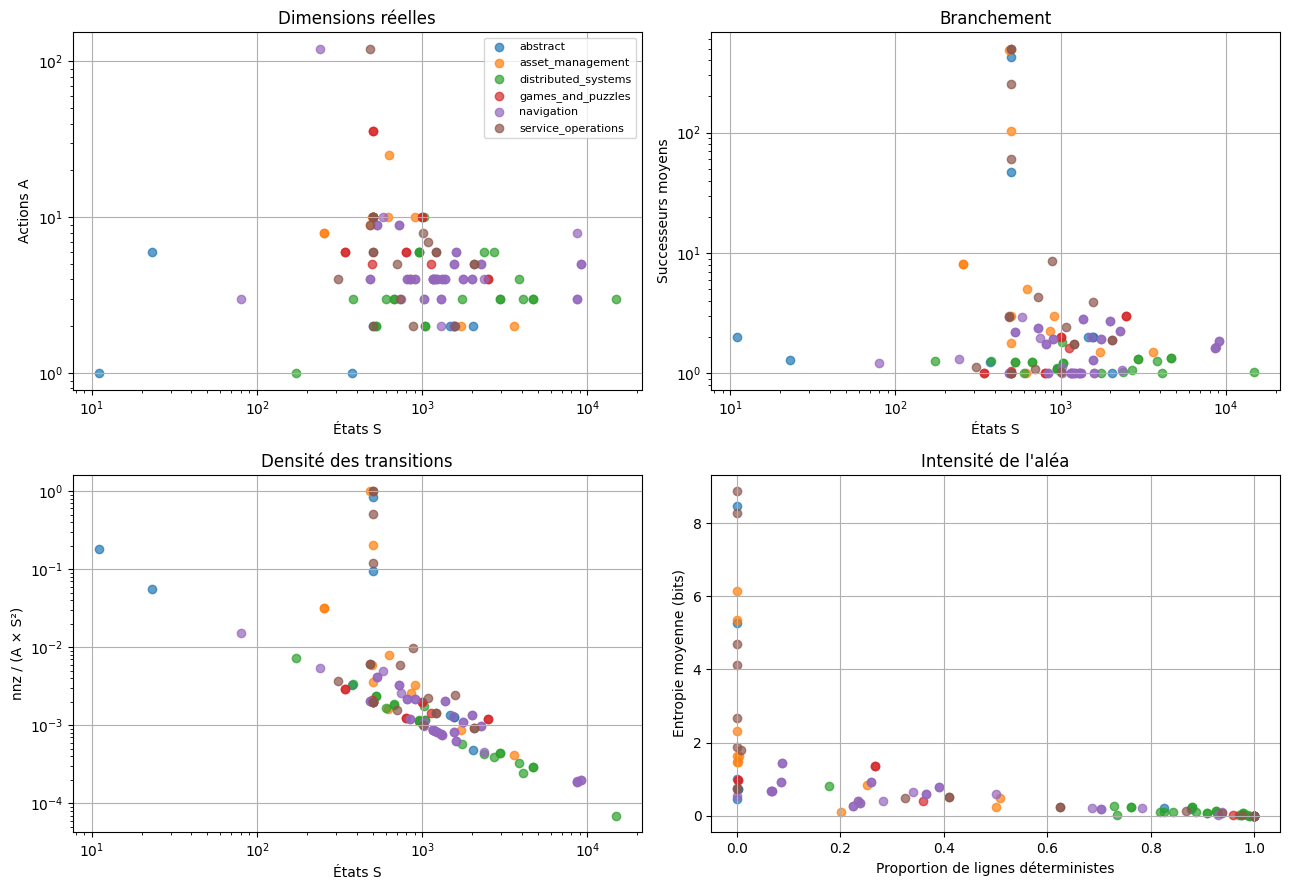

,model_id,preset,transition_nnz,successors_min,successors_median,successors_p90,successors_max,deterministic_share,self_loop_mass_mean,row_sum_error_max
0,discounted:access_control,tiny,253984.0,4.0,254.0,452.4,500.0,0.000000,0.033261,2.220446e-16
1,discounted:acrobot,tiny,3891.0,1.0,1.0,1.0,1.0,1.000000,0.003598,0.000000e+00
2,discounted:admission,tiny,15151.0,5.0,9.0,9.0,17.0,0.000000,0.262384,1.110223e-16
3,discounted:ambulance,tiny,2490000.0,498.0,498.0,498.0,498.0,0.000000,0.002000,0.000000e+00
4,discounted:ambulance_relocation,tiny,2500000.0,500.0,500.0,500.0,500.0,0.000000,0.002000,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...
134,total:taxi,tiny,3006.0,1.0,1.0,1.0,1.0,1.000000,0.461078,0.000000e+00
135,total:tireworld,tiny,10130.0,1.0,1.0,2.0,2.0,0.702945,0.473239,0.000000e+00
136,total:windgrid,tiny,4896.0,1.0,1.0,1.0,1.0,1.000000,0.055556,0.000000e+00
137,total:wumpus_world,tiny,9600.0,1.0,1.0,1.0,1.0,1.000000,0.719583,0.000000e+00


In [10]:
if not metrics.empty:
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    for category, group in metrics.groupby("category"):
        axes[0, 0].scatter(group.states, group.actions, label=category, alpha=0.7)
        axes[0, 1].scatter(group.states, group.successors_mean, alpha=0.7)
        axes[1, 0].scatter(group.states, group.transition_density, alpha=0.7)
        axes[1, 1].scatter(
            group.deterministic_share, group.entropy_bits_mean, alpha=0.7
        )
    for axis in axes[0]:
        axis.set_xscale("log")
        axis.set_yscale("log")
    axes[1, 0].set_xscale("log")
    axes[1, 0].set_yscale("log")
    axes[0, 0].set(xlabel="États S", ylabel="Actions A", title="Dimensions réelles")
    axes[0, 1].set(xlabel="États S", ylabel="Successeurs moyens", title="Branchement")
    axes[1, 0].set(
        xlabel="États S", ylabel="nnz / (A × S²)", title="Densité des transitions"
    )
    axes[1, 1].set(
        xlabel="Proportion de lignes déterministes",
        ylabel="Entropie moyenne (bits)",
        title="Intensité de l'aléa",
    )
    axes[0, 0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()
    display(
        metrics[
            [
                "model_id",
                "preset",
                "transition_nnz",
                "successors_min",
                "successors_median",
                "successors_p90",
                "successors_max",
                "deterministic_share",
                "self_loop_mass_mean",
                "row_sum_error_max",
            ]
        ]
    )

## 6. Récompenses et décisions

L'amplitude des récompenses est conservée dans les unités natives. Les valeurs négatives ne sont pas automatiquement étiquetées « coûts » : le sens de l'objectif doit être lu dans la description ou annoté. Une récompense identique entre actions n'implique pas l'absence de décision, puisque les transitions peuvent différer.

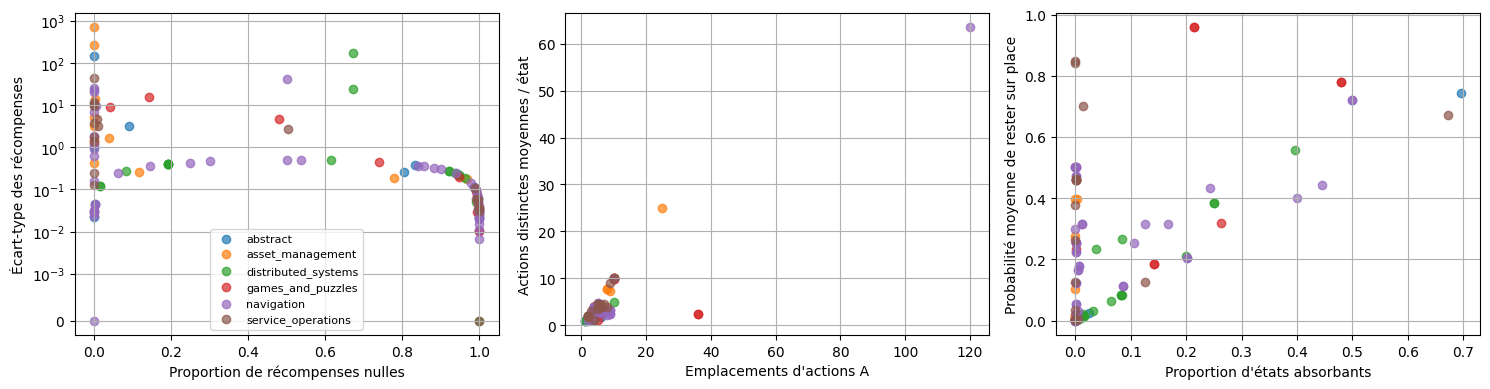

,model_id,preset,reward_min,reward_p10,reward_median,reward_p90,reward_max,reward_mean,reward_std,reward_zero_share,reward_positive_share,reward_negative_share,reward_constant,reward_action_varying_state_share,distinct_action_share,single_choice_state_share
0,discounted:access_control,tiny,0.000,0.000000,0.000000,8.000000,8.000000,1.860000,2.660902,0.504000,0.496000,0.000000,False,0.992000,0.996000,0.008000
1,discounted:acrobot,tiny,-1.000,-1.000000,-1.000000,0.000000,0.000000,-0.855307,0.351791,0.144693,0.000000,0.855307,False,0.004626,0.356978,0.929067
2,discounted:admission,tiny,-14.600,-9.400000,-5.400000,-1.200000,-0.000000,-5.462415,3.161636,0.011905,0.000000,0.988095,False,0.816327,0.908163,0.183673
3,discounted:ambulance,tiny,0.000,0.277355,0.690158,0.944355,1.000000,0.647851,0.248013,0.000400,0.999600,0.000000,False,1.000000,NaN,NaN
4,discounted:ambulance_relocation,tiny,-0.775,-0.630843,-0.404135,-0.301812,-0.257089,-0.439903,0.125491,0.000000,0.000000,1.000000,False,1.000000,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
134,total:taxi,tiny,0.000,0.000000,0.000000,0.000000,1.000000,0.001331,0.036454,0.998669,0.001331,0.000000,False,0.007984,0.705589,0.001996
135,total:tireworld,tiny,0.000,0.000000,0.000000,0.000000,1.000000,0.006146,0.078155,0.993854,0.006146,0.000000,False,0.002561,0.596927,0.130602
136,total:windgrid,tiny,0.000,0.000000,0.000000,0.000000,1.000000,0.000817,0.028571,0.999183,0.000817,0.000000,False,0.003268,0.996936,0.000817
137,total:wumpus_world,tiny,0.000,0.000000,0.000000,0.000000,1.000000,0.001667,0.040791,0.998333,0.001667,0.000000,False,0.010000,0.447083,0.500000


In [11]:
if not metrics.empty:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for category, group in metrics.groupby("category"):
        axes[0].scatter(
            group.reward_zero_share, group.reward_std, label=category, alpha=0.7
        )
        axes[1].scatter(group.actions, group.distinct_actions_mean, alpha=0.7)
        axes[2].scatter(group.absorbing_share, group.self_loop_mass_mean, alpha=0.7)
    axes[0].set(
        xlabel="Proportion de récompenses nulles", ylabel="Écart-type des récompenses"
    )
    axes[0].set_yscale("symlog", linthresh=1e-3)
    axes[1].set(
        xlabel="Emplacements d'actions A", ylabel="Actions distinctes moyennes / état"
    )
    axes[2].set(
        xlabel="Proportion d'états absorbants",
        ylabel="Probabilité moyenne de rester sur place",
    )
    axes[0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()
    display(
        metrics[
            [
                "model_id",
                "preset",
                "reward_min",
                "reward_p10",
                "reward_median",
                "reward_p90",
                "reward_max",
                "reward_mean",
                "reward_std",
                "reward_zero_share",
                "reward_positive_share",
                "reward_negative_share",
                "reward_constant",
                "reward_action_varying_state_share",
                "distinct_action_share",
                "single_choice_state_share",
            ]
        ]
    )

## 7. Lecture d'une instance

L'aperçu montre seulement les premiers états, dans leur ordre natif, et une action choisie. Le bloc de transition peut omettre de la probabilité qui sort de ce bloc ; ses lignes ne sont donc pas nécessairement de somme 1. L'ordre des états peut masquer ou créer une apparence de structure. Les histogrammes, eux, portent sur tous les couples état-action de cette instance. Les indices d'actions sont des emplacements locaux, sans sens commun garanti entre états ou modèles.

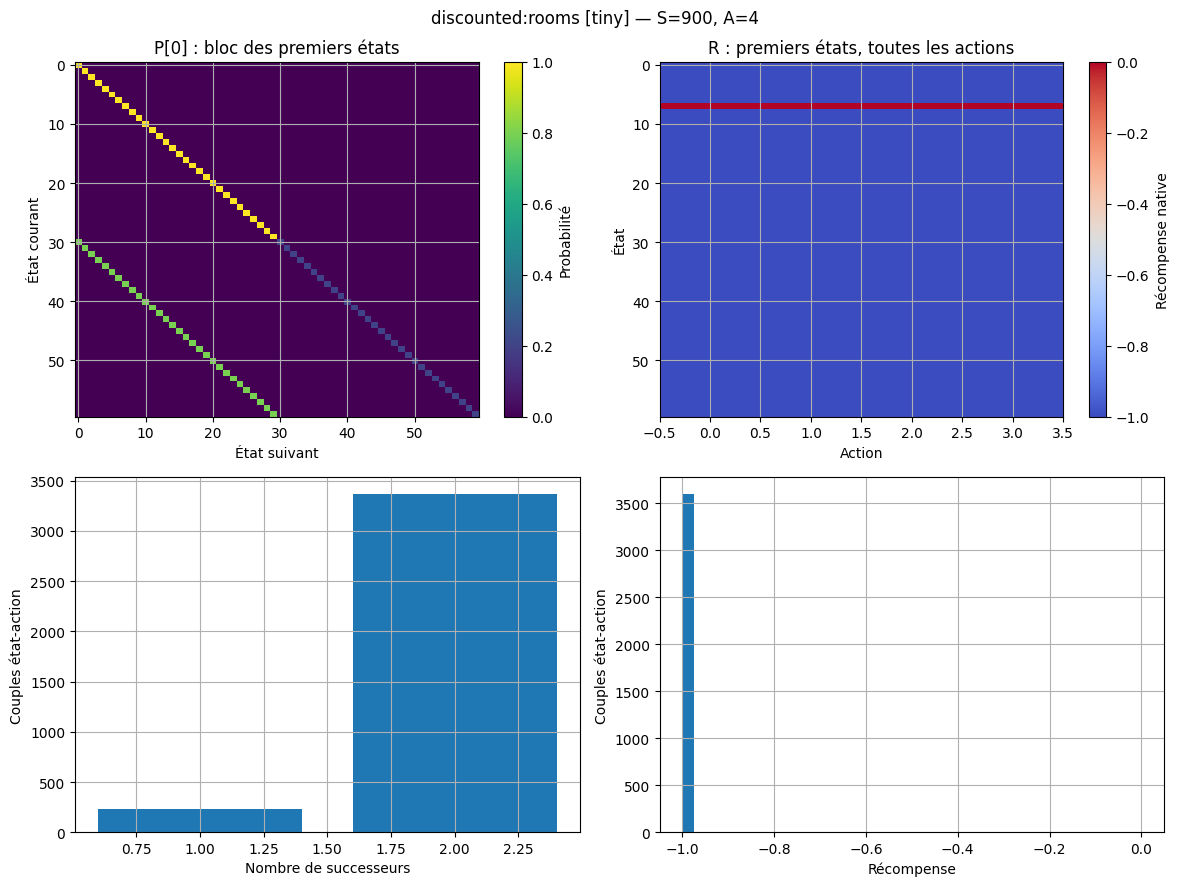

,action,transition_nnz,transition_density,successors_min,successors_median,successors_p90,successors_max,successors_mean,deterministic_share,self_loop_mass_mean,entropy_bits_mean,row_sum_error_max,model_id,preset,reward_min,reward_max,reward_zero_share
552,0,1742,0.002151,1,2.0,2.0,2,1.935556,0.064444,0.251556,0.675404,0.0,discounted:rooms,tiny,-1.0,0.0,0.001111
553,1,1741,0.002149,1,2.0,2.0,2,1.934444,0.065556,0.252444,0.674602,0.0,discounted:rooms,tiny,-1.0,0.0,0.001111
554,2,1741,0.002149,1,2.0,2.0,2,1.934444,0.065556,0.252444,0.674602,0.0,discounted:rooms,tiny,-1.0,0.0,0.001111
555,3,1741,0.002149,1,2.0,2.0,2,1.934444,0.065556,0.252444,0.674602,0.0,discounted:rooms,tiny,-1.0,0.0,0.001111


In [12]:
if preview is None:
    print(
        f"Pas d'aperçu pour {PREVIEW_ID} [{PREVIEW_PRESET}] : voir le bilan d'analyse."
    )
else:
    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    image = axes[0, 0].imshow(
        preview["transition"], aspect="auto", interpolation="nearest", vmin=0, vmax=1
    )
    axes[0, 0].set(
        title=f"P[{PREVIEW_ACTION}] : bloc des premiers états",
        xlabel="État suivant",
        ylabel="État courant",
    )
    fig.colorbar(image, ax=axes[0, 0], label="Probabilité")
    image = axes[0, 1].imshow(
        preview["reward"], aspect="auto", interpolation="nearest", cmap="coolwarm"
    )
    axes[0, 1].set(
        title="R : premiers états, toutes les actions", xlabel="Action", ylabel="État"
    )
    fig.colorbar(image, ax=axes[0, 1], label="Récompense native")
    successors, counts = np.unique(preview["successors"], return_counts=True)
    axes[1, 0].bar(successors, counts)
    axes[1, 0].set(xlabel="Nombre de successeurs", ylabel="Couples état-action")
    axes[1, 1].hist(preview["reward_values"], bins=40)
    axes[1, 1].set(xlabel="Récompense", ylabel="Couples état-action")
    fig.suptitle(
        f"{PREVIEW_ID} [{PREVIEW_PRESET}] — S={preview['states']}, A={preview['actions']}"
    )
    plt.tight_layout()
    plt.show()
    display(
        per_action.loc[
            (per_action.model_id == PREVIEW_ID) & (per_action.preset == PREVIEW_PRESET)
        ]
    )

## 8. Couverture structurelle, proximités et limites

Les classes ci-dessous servent à lire la couverture : elles ne constituent pas une mesure universelle de diversité. « Mixte » signifie que certaines lignes sont déterministes et d'autres stochastiques. Un état absorbant observé n'établit pas qu'il sera atteint. Les proportions de récompenses sont conservées dans les tables détaillées.

Les empreintes signalent des matrices identiques après canonicalisation, dans le même ordre d'états et d'actions. Elles peuvent révéler deux presets donnant la même instance. Elles ne détectent pas les équivalences après permutation, les parentés de tâche ou toutes les transformations possibles des récompenses. Aucun score global ni classement de difficulté n'est calculé.

In [13]:
if not metrics.empty:
    metrics["dynamics_class"] = np.select(
        [metrics.deterministic_share == 1, metrics.deterministic_share == 0],
        ["déterministe", "stochastique partout"],
        default="mixte",
    )
    metrics["absorption_class"] = np.where(
        metrics.absorbing_states > 0, "avec état absorbant", "sans état absorbant"
    )
    metrics["reward_class"] = np.select(
        [metrics.reward_constant.to_numpy(dtype=bool), metrics.reward_zero_share > 0],
        ["constante", "variable avec zéros"],
        default="variable sans zéro",
    )
    for property_name in ("dynamics_class", "absorption_class", "reward_class"):
        print(f"Instances par catégorie et {property_name}")
        display(pd.crosstab(metrics.category, metrics[property_name]))
    structural_coverage = pd.crosstab(
        [metrics.category, metrics.dynamics_class],
        [metrics.absorption_class, metrics.reward_class],
    )
    display(structural_coverage)
    graph_columns = [
        "model_id",
        "preset",
        "absorbing_states",
        "declared_terminal_states",
        "declared_initial_states",
        "graph_status",
        "scc_count",
        "largest_scc_share",
        "sink_scc_count",
        "nontrivial_cycle_state_share",
    ]
    display(metrics.reindex(columns=graph_columns))
    duplicates = metrics.loc[
        metrics.duplicated("matrix_sha256", keep=False)
    ].sort_values("matrix_sha256")
    display(duplicates[["model_id", "preset", "states", "actions", "matrix_sha256"]])
    display(
        metrics.groupby(["category", "preset"])[
            [
                "states",
                "actions",
                "successors_mean",
                "deterministic_share",
                "reward_zero_share",
            ]
        ].agg(["min", "median", "max"])
    )

annotation_audit = selected.assign(
    missing_description=selected.description.fillna("").eq(""),
    missing_family=~selected.family_reviewed,
    missing_origin=selected.origin.isna(),
    missing_objective=selected.objective.isna(),
    missing_temporal_type=selected.temporal_type.isna(),
)
display(
    annotation_audit[
        [
            "model_id",
            "missing_description",
            "missing_family",
            "missing_origin",
            "missing_objective",
            "missing_temporal_type",
        ]
    ]
)

Instances par catégorie et dynamics_class


dynamics_class,déterministe,mixte,stochastique partout
category,,,
abstract,2,4,4
asset_management,1,7,4
distributed_systems,0,23,0
games_and_puzzles,6,6,0
navigation,20,29,1
service_operations,2,10,7


Instances par catégorie et absorption_class


absorption_class,avec état absorbant,sans état absorbant
category,,
abstract,5,5
asset_management,2,10
distributed_systems,23,0
games_and_puzzles,12,0
navigation,44,6
service_operations,10,9


Instances par catégorie et reward_class


reward_class,constante,variable avec zéros,variable sans zéro
category,,,
abstract,0,8,2
asset_management,0,6,6
distributed_systems,1,22,0
games_and_puzzles,0,12,0
navigation,1,48,1
service_operations,1,15,3


absorption_class                         avec état absorbant  \
reward_class                                       constante   
category            dynamics_class                             
abstract            déterministe                           0   
                    mixte                                  0   
                    stochastique partout                   0   
asset_management    déterministe                           0   
                    mixte                                  0   
                    stochastique partout                   0   
distributed_systems mixte                                  1   
games_and_puzzles   déterministe                           0   
                    mixte                                  0   
navigation          déterministe                           1   
                    mixte                                  0   
                    stochastique partout                   0   
service_operations  déterministe                           0   
                    mixte                                  1   
                    stochastique partout                   0   

absorption_class                                              \
reward_class                             variable avec zéros   
category            dynamics_class                             
abstract            déterministe                           1   
                    mixte                                  4   
                    stochastique partout                   0   
asset_management    déterministe                           0   
                    mixte                                  2   
                    stochastique partout                   0   
distributed_systems mixte                                 22   
games_and_puzzles   déterministe                           6   
                    mixte                                  6   
navigation          déterministe                          16   
                    mixte                                 27   
                    stochastique partout                   0   
service_operations  déterministe                           2   
                    mixte                                  7   
                    stochastique partout                   0   

absorption_class                         sans état absorbant  \
reward_class                             variable avec zéros   
category            dynamics_class                             
abstract            déterministe                           1   
                    mixte                                  0   
                    stochastique partout                   2   
asset_management    déterministe                           1   
                    mixte                                  1   
                    stochastique partout                   2   
distributed_systems mixte                                  0   
games_and_puzzles   déterministe                           0   
                    mixte                                  0   
navigation          déterministe                           3   
                    mixte                                  2   
                    stochastique partout                   0   
service_operations  déterministe                           0   
                    mixte                                  2   
                    stochastique partout                   4   

absorption_class                                             
reward_class                             variable sans zéro  
category            dynamics_class                           
abstract            déterministe                          0  
                    mixte                                 0  
                    stochastique partout                  2  
asset_management    déterministe                          0  
                    mixte                                 4  
                    stochastique partout     

,model_id,preset,absorbing_states,declared_terminal_states,declared_initial_states,graph_status,scc_count,largest_scc_share,sink_scc_count,nontrivial_cycle_state_share
0,discounted:access_control,tiny,0.0,NaN,NaN,computed,1.0,1.000000,1.0,1.000000
1,discounted:acrobot,tiny,4.0,1.0,NaN,computed,1273.0,0.004626,12.0,0.028527
2,discounted:admission,tiny,0.0,NaN,NaN,computed,16.0,0.982993,1.0,0.982993
3,discounted:ambulance,tiny,0.0,NaN,NaN,computed,3.0,0.996000,1.0,0.996000
4,discounted:ambulance_relocation,tiny,0.0,NaN,NaN,computed,1.0,1.000000,1.0,1.000000
...,...,...,...,...,...,...,...,...,...,...
134,total:taxi,tiny,1.0,1.0,NaN,computed,21.0,0.049900,1.0,0.998004
135,total:tireworld,tiny,2.0,2.0,NaN,computed,398.0,0.004481,2.0,0.869398
136,total:windgrid,tiny,1.0,1.0,NaN,computed,17.0,0.986928,1.0,0.986928
137,total:wumpus_world,tiny,800.0,800.0,NaN,computed,828.0,0.057500,800.0,0.500000


,model_id,preset,states,actions,matrix_sha256
30,discounted:jani_beb_modest,tiny,4660.0,3.0,0eb7f2844862bf9301522fe55e7457ba2b1653799f4cd0ea98528e1615489ccc
60,discounted:qvbs_beb,tiny,4660.0,3.0,0eb7f2844862bf9301522fe55e7457ba2b1653799f4cd0ea98528e1615489ccc


states                  actions                \
                              min  median      max     min median    max   
category            preset                                                 
abstract            tiny     11.0   500.0   2040.0     1.0    2.0   10.0   
asset_management    tiny    256.0   560.0   3601.0     2.0    9.5   25.0   
distributed_systems tiny    173.0  1038.0  14824.0     1.0    3.0   10.0   
games_and_puzzles   tiny    343.0   800.0   2502.0     4.0    6.0   36.0   
navigation          tiny     80.0  1224.0   9122.0     2.0    4.0  120.0   
service_operations  tiny    309.0   700.0   2050.0     2.0    6.0  121.0   

                           successors_mean                        \
                                       min    median         max   
category            preset                                         
abstract            tiny          1.000000  1.998718  425.150200   
asset_management    tiny          1.000000  2.997401  484.000000   
distributed_systems tiny          1.008223  1.238636    1.821310   
games_and_puzzles   tiny          1.000000  1.024096    3.009193   
navigation          tiny          1.000000  1.305552    2.924483   
service_operations  tiny          1.000000  2.434788  500.000000   

                           deterministic_share                      \
                                           min    median       max   
category            preset                                           
abstract            tiny              0.000000  0.001282  1.000000   
asset_management    tiny              0.000000  0.002503  1.000000   
distributed_systems tiny              0.178690  0.909344  0.991777   
games_and_puzzles   tiny              0.001998  0.979920  1.000000   
navigation          tiny              0.000000  0.694448  1.000000   
service_operations  tiny              0.000000  0.325265  1.000000   

                           reward_zero_share                      
                                         min    median       max  
category            preset                                        
abstract            tiny            0.000000  0.447628  0.999359  
asset_management    tiny            0.000000  0.000100  0.968750  
distributed_systems tiny            0.015152  0.921199  1.000000  
games_and_puzzles   tiny            0.040767  0.992880  0.999889  
navigation          tiny            0.000000  0.689536  0.999931  
service_operations  tiny            0.000000  0.007429  1.000000

,model_id,missing_description,missing_family,missing_origin,missing_objective,missing_temporal_type
0,discounted:access_control,False,True,True,True,True
1,discounted:acrobot,False,True,True,True,True
2,discounted:admission,False,True,True,True,True
3,discounted:ambulance,False,True,True,True,True
4,discounted:ambulance_relocation,False,True,True,True,True
...,...,...,...,...,...,...
134,total:taxi,False,True,True,True,True
135,total:tireworld,False,True,True,True,True
136,total:windgrid,False,True,True,True,True
137,total:wumpus_world,False,True,True,True,True


### Questions à examiner après chaque relance

- Quelles catégories et familles dominent la sélection ? La réponse change-t-elle en comptant les instances ?
- Les domaines représentés couvrent-ils plusieurs formes de dynamique, de décision et de récompense ?
- Les nouvelles recettes apportent-elles une tâche différente, une structure différente, ou surtout une nouvelle taille ?
- Quels modèles restent sans annotation, indisponibles ou hors budget ? Ces exclusions concentrent-elles l'analyse sur certains domaines ?
- Plusieurs presets donnent-ils exactement les mêmes matrices ? Les structures changent-elles avec la taille lorsque plusieurs presets ont été analysés ?

Une case vide est une absence observée dans le périmètre analysé, pas la preuve d'un manque scientifique. La portée dépend des catégories du catalogue, de la qualité des annotations et des presets construits. Une seule graine et un seul preset ne décrivent pas toute la variété d'un générateur. La connectivité, les récompenses et les dimensions seules ne permettent pas de prédire les performances des solveurs.

## 9. Export et comparaison entre relances

Chaque relance exportée crée un répertoire daté sous `artifacts/tmp/model_diversity/`, avec inventaire, presets, résultats, descriptions par action, annotations et manifeste. Les tableaux complets peuvent être filtrés dans le notebook ou lus depuis les CSV. Ce dossier est ignoré par Git ; copier une campagne à conserver vers un emplacement de référence choisi explicitement.

La comparaison utilise le dernier export ayant exactement le même protocole et le même périmètre de filtres. Elle distingue les recettes ajoutées ou retirées, les métadonnées modifiées, les changements de statut et les changements de matrices parmi les instances analysées dans les deux relances. Une empreinte différente peut aussi venir d'une graine, d'une dépendance ou d'un ordre d'états différent. La présence préalable du cache ne prouve pas qu'il a été utilisé ; une modification de recette conservant un ancien nom peut nécessiter un rafraîchissement explicite du cache.

In [14]:
def package_version(name):
    """Lire une version installée si elle est disponible."""
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return None


def git_output(*arguments):
    """Lire l'état du dépôt sans le modifier."""
    try:
        return subprocess.run(
            ["git", "-C", str(REPO_ROOT), *arguments],
            check=True,
            capture_output=True,
            text=True,
            timeout=5,
        ).stdout.strip()
    except (OSError, subprocess.SubprocessError):
        return None


protocol = {
    "schema": 1,
    "criteria": list(CRITERIA),
    "model_ids": None if MODEL_IDS is None else sorted(MODEL_IDS),
    "categories": None if CATEGORIES is None else sorted(CATEGORIES),
    "presets": list(PRESETS),
    "analyze_matrices": ANALYZE_MATRICES,
    "seed": SEED,
    "cache_mode": CACHE_MODE,
    "atol": ATOL,
    "max_requested_states": MAX_REQUESTED_STATES,
    "max_actual_states": MAX_ACTUAL_STATES,
    "max_state_actions": MAX_STATE_ACTIONS,
    "max_transition_nnz": MAX_TRANSITION_NNZ,
    "analyze_graph": ANALYZE_GRAPH,
    "max_action_comparison_work": MAX_ACTION_COMPARISON_WORK,
}
notebook_path = REPO_ROOT / "notebooks/model_diversity.ipynb"
manifest = {
    "created_at": datetime.now(timezone.utc).isoformat(),
    "protocol": protocol,
    "git_commit": git_output("rev-parse", "HEAD"),
    "git_status": git_output("status", "--porcelain"),
    "notebook_sha256": hashlib.sha256(notebook_path.read_bytes()).hexdigest(),
    "python": platform.python_version(),
    "platform": platform.platform(),
    "packages": {
        name: package_version(name)
        for name in ("mdpforge", "numpy", "scipy", "pandas", "matplotlib", "mazelib")
    },
    "catalogue_recipes": len(catalogue),
    "selected_recipes": len(selected),
    "planned_instances": len(instances),
    "analyzed_instances": len(metrics),
    "annotations": ANNOTATIONS,
    "solver_runs": 0,
}

previous_dir = None
if OUTPUT_ROOT.exists():
    for candidate in sorted(OUTPUT_ROOT.iterdir(), reverse=True):
        manifest_path = candidate / "manifest.json"
        if manifest_path.is_file():
            try:
                previous_manifest = json.loads(
                    manifest_path.read_text(encoding="utf-8")
                )
                if (
                    previous_manifest.get("protocol") == protocol
                    and (candidate / "inventory.json").is_file()
                ):
                    previous_dir = candidate
                    break
            except (OSError, ValueError) as exc:
                print(f"Export précédent illisible {candidate.name}: {exc}")

if previous_dir is None:
    print("Aucun export précédent avec le même protocole.")
else:
    previous_inventory = json.loads(
        (previous_dir / "inventory.json").read_text(encoding="utf-8")
    )
    current_inventory = {
        row["model_id"]: entries_by_id[row["model_id"]]
        for row in selected.to_dict("records")
    }
    added = sorted(current_inventory.keys() - previous_inventory.keys())
    removed = sorted(previous_inventory.keys() - current_inventory.keys())
    changed = sorted(
        key
        for key in current_inventory.keys() & previous_inventory.keys()
        if current_inventory[key] != previous_inventory[key]
    )
    print(f"Comparaison à {previous_dir.name}")
    display(
        pd.DataFrame(
            [
                {"change": label, "model_ids": values}
                for label, values in (
                    ("ajouts", added),
                    ("retraits", removed),
                    ("métadonnées", changed),
                )
            ]
        )
    )
    previous_instances = pd.read_csv(previous_dir / "instances.csv")
    keys = ["model_id", "preset"]
    comparison_columns = keys + [
        "status",
        "matrix_sha256",
        "states",
        "actions",
        "transition_nnz",
        "reward_min",
        "reward_max",
    ]
    comparison = previous_instances.reindex(columns=comparison_columns).merge(
        instances.reindex(columns=comparison_columns),
        on=keys,
        how="outer",
        suffixes=("_before", "_now"),
        indicator=True,
    )
    comparison["matrix_changed"] = (
        comparison.status_before.eq("analyzed")
        & comparison.status_now.eq("analyzed")
        & comparison.matrix_sha256_before.ne(comparison.matrix_sha256_now)
    )
    display(
        comparison.loc[
            comparison._merge.ne("both")
            | comparison.status_before.ne(comparison.status_now)
            | comparison.matrix_changed
        ]
    )

if EXPORT:
    output_dir = OUTPUT_ROOT / datetime.now(timezone.utc).strftime(
        "%Y-%m-%d_%H-%M-%S_%f"
    )
    output_dir.mkdir(parents=True, exist_ok=False)
    for name, table in {
        "catalogue": catalogue,
        "presets": presets,
        "instances": instances,
        "metrics": metrics,
        "per_action": per_action,
        "annotation_audit": annotation_audit,
    }.items():
        csv_table = table.copy()
        for column in csv_table:
            if csv_table[column].dtype != object:
                continue
            csv_table[column] = csv_table[column].map(
                lambda value: (
                    json.dumps(value, ensure_ascii=False, sort_keys=True)
                    if isinstance(value, (dict, list, tuple))
                    else value
                )
            )
        csv_table.to_csv(output_dir / f"{name}.csv", index=False, encoding="utf-8")
    inventory = {
        row["model_id"]: entries_by_id[row["model_id"]]
        for row in selected.to_dict("records")
    }
    (output_dir / "inventory.json").write_text(
        json.dumps(inventory, indent=2, ensure_ascii=False), encoding="utf-8"
    )
    (output_dir / "manifest.json").write_text(
        json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8"
    )
    print(f"Export : {output_dir}")
else:
    print("Export désactivé.")

Aucun export précédent avec le même protocole.
Export : C:\Users\orsof\github\mdpforge\artifacts\tmp\model_diversity\2026-11-18_11-24-45_281373
